<a href="https://colab.research.google.com/github/AboRady5/Computer-Vision-Tasks/blob/master/CIFAR10_CNN_vs_EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10 Image Classification

This notebook compares a simple CNN trained from scratch with EfficientNetB0 using pretrained ImageNet weights. Both models are trained on the CIFAR-10 dataset, then their results are compared.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TensorFlow version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load the dataset

CIFAR-10 is available directly through Keras, so there is no need to download it manually. It contains 10 classes of images.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Keep 5,000 images from the training set for validation.
np.random.seed(42)
indices = np.random.permutation(len(x_train))
x_train, y_train = x_train[indices], y_train[indices]

x_val, y_val = x_train[:5000], y_train[:5000]
x_train, y_train = x_train[5000:], y_train[5000:]

print('Training images:', len(x_train))
print('Validation images:', len(x_val))
print('Test images:', len(x_test))
print('Classes:', class_names)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1680s 10us/step
Training images: 45000
Validation images: 5000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Take a look at some images

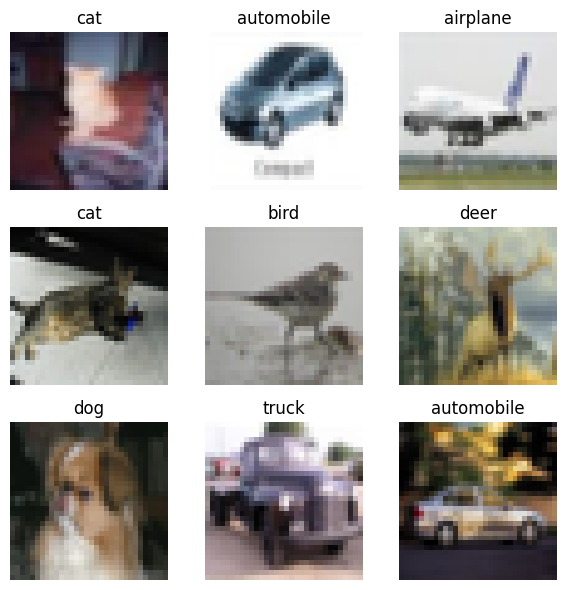

In [3]:
plt.figure(figsize=(6, 6))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis('off')

plt.tight_layout()
plt.show()

## Prepare the images

The original images are 32 × 32 pixels. We'll resize them to 150 × 150 so they can be used by EfficientNetB0, and use batches of 32 images.

In [4]:
img_size = (150, 150)
batch_size = 32

def prepare_image(image, label):
    image = tf.image.resize(tf.cast(image, tf.float32), img_size)
    label = tf.cast(tf.squeeze(label), tf.int32)
    return image, label

def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(10000)
    dataset = dataset.map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)

## CNN

First, we'll train a small CNN from scratch.

In [5]:
cnn_model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,642 (18.42 MB)

 Trainable params: 4,829,642 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### Train the CNN

In [6]:
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 57s 33ms/step - accuracy: 0.3829 - loss: 1.6919 - val_accuracy: 0.4828 - val_loss: 1.4232
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 36s 25ms/step - accuracy: 0.4928 - loss: 1.4101 - val_accuracy: 0.5644 - val_loss: 1.2171
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 26ms/step - accuracy: 0.5461 - loss: 1.2725 - val_accuracy: 0.5960 - val_loss: 1.1527
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 26ms/step - accuracy: 0.5860 - loss: 1.1658 - val_accuracy: 0.6170 - val_loss: 1.0770
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 26ms/step - accuracy: 0.6172 - loss: 1.0743 - val_accuracy: 0.6382 - val_loss: 1.0188
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.6445 - loss: 0.9985 - val_accuracy: 0.6524 - val_loss: 0.9750
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.6652 - loss: 0.9353 - val_accuracy: 0.6576 - val_loss: 0.9874
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 26ms/step - accuracy: 0.6894 -

In [7]:
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds)
print('CNN Test Accuracy:', cnn_test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6569 - loss: 1.1548
CNN Test Accuracy: 0.6568999886512756


## EfficientNetB0

Now we'll use EfficientNetB0 with ImageNet weights. Its original classification layer is removed, and its pretrained layers are frozen. We'll add a new output layer for the 10 CIFAR-10 classes.

In [8]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(150, 150, 3)
)

base_model.trainable = False

eff_model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

eff_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

eff_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### Train EfficientNetB0

In [9]:
eff_history = eff_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 111s 49ms/step - accuracy: 0.8525 - loss: 0.4554 - val_accuracy: 0.9046 - val_loss: 0.2808
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 33s 24ms/step - accuracy: 0.8852 - loss: 0.3352 - val_accuracy: 0.9102 - val_loss: 0.2550
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.8927 - loss: 0.3162 - val_accuracy: 0.9150 - val_loss: 0.2461
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.8966 - loss: 0.3029 - val_accuracy: 0.9176 - val_loss: 0.2466
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.8988 - loss: 0.2994 - val_accuracy: 0.9146 - val_loss: 0.2397
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.8994 - loss: 0.2967 - val_accuracy: 0.9160 - val_loss: 0.2418
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.8983 - loss: 0.2947 - val_accuracy: 0.9142 - val_loss: 0.2397
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - accuracy: 0.8990 

In [10]:
eff_test_loss, eff_test_acc = eff_model.evaluate(test_ds)
print('EfficientNetB0 Test Accuracy:', eff_test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.9123 - loss: 0.2648
EfficientNetB0 Test Accuracy: 0.9122999906539917


## Compare the results

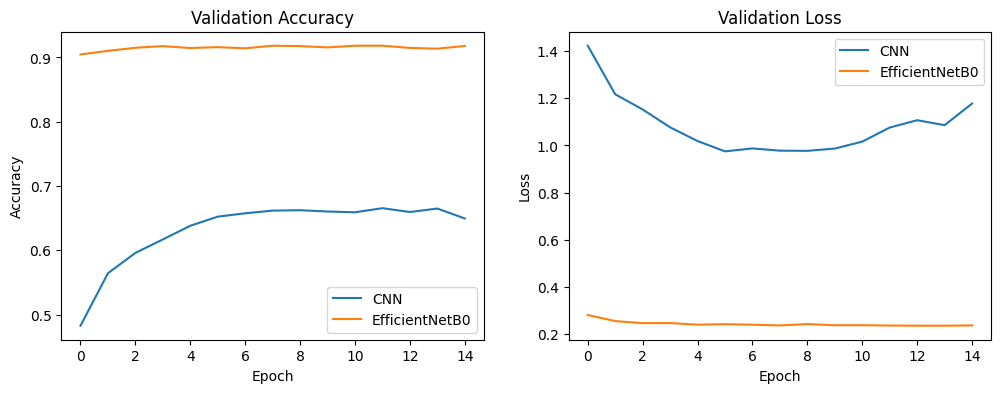

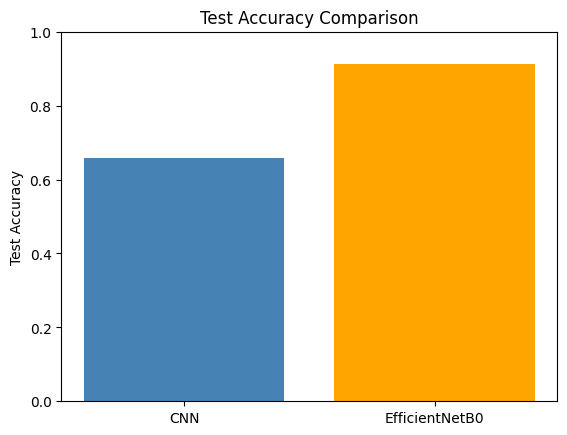

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['val_accuracy'], label='CNN')
plt.plot(eff_history.history['val_accuracy'], label='EfficientNetB0')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['val_loss'], label='CNN')
plt.plot(eff_history.history['val_loss'], label='EfficientNetB0')
plt.title('Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

plt.bar(['CNN', 'EfficientNetB0'], [cnn_test_acc, eff_test_acc], color=['steelblue', 'orange'])
plt.ylim(0, 1)
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Comparison')
plt.show()